## Duszkiewicz et al.
#### Local origin of excitatory–inhibitory tuning equivalence in a cortical network

Data from https://dandiarchive.org/dandiset/000939

Old version of data + more data + matlab code to recreate figures at https://figshare.com/articles/dataset/Local_origin_of_excitatory-inhibitory_tuning_equivalence_in_a_cortical_network_Duszkiewicz_et_al_2024_/24921252

### Using new data

In [ ]:
% cd ../data/dusz/
! dandi download DANDI:000939/0.240528.1542

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pynwb import NWBHDF5IO 

data_path = '../data/dusz/000939'

import os

os.listdir(data_path)

['sub-A3716',
 'sub-A3701',
 'sub-A3712',
 'sub-A3710',
 'sub-A3711',
 'sub-A3730',
 'sub-A3702',
 'sub-A3703',
 'sub-A6216',
 'sub-A3713',
 'sub-A6211',
 'sub-A1808',
 'sub-A3709',
 '.ipynb_checkpoints',
 'sub-A9701',
 'sub-A1821',
 'sub-A1824',
 'sub-A3728',
 'sub-A3717',
 'sub-A3706',
 'sub-A3707',
 'sub-A1813',
 'sub-A1815',
 'sub-A5505',
 'sub-A3708',
 'sub-A5508',
 'sub-A3705',
 'sub-A5506',
 'sub-A5507',
 'sub-A5801',
 'sub-A6215',
 'sub-A3723',
 'dandiset.yaml']

In [2]:
session = 'sub-A3711'

filepath = os.listdir(f'{data_path}/{session}')[0]
print(filepath)

io = NWBHDF5IO(f'{data_path}/{session}/{filepath}', mode="r")
nwbfile = io.read()
nwbfile

sub-A3711_behavior+ecephys.nwb


/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.6.0-alpha because version 2.7.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


Data type,object
Shape,"(5,)"
Array size,40.00 bytes
Chunk shape,None
Compression,None
Compression opts,None
Compression ratio,0.5
Data type,float64
Shape,"(485726,)"
Array size,3.71 MiB
Chunk shape,None


In [3]:
# accel data is diff timestamps than pos and hd (so is lfp)

headings = nwbfile.processing['behavior'].data_interfaces['CompassDirection'].spatial_series['head-direction'].data[:]   # rad
positions = nwbfile.processing['behavior'].data_interfaces['Position'].spatial_series['position'].data[:]                # cm
ts = nwbfile.processing['behavior'].data_interfaces['CompassDirection'].spatial_series['head-direction'].timestamps[:]

positions = np.hstack((ts.reshape(-1, 1), positions, headings.reshape(-1, 1)))

epochs_df = nwbfile.epochs[:] # dataframe of start/stop times for positions
explore_start = epochs_df['start_time'].loc[1]
explore_stop = epochs_df['stop_time'].loc[1]

units_df = nwbfile.units[:]
spike_times = []
for i, row in units_df.iterrows():
    spike_times.extend([[st, i] for st in row['spike_times']])
spike_times = np.array(spike_times)
spike_times = np.sort(spike_times, axis=0)
spike_times = spike_times[(explore_start < spike_times[:, 0]) & (spike_times[:, 0] < explore_stop)]

positions = positions[(explore_start < positions[:, 0]) & (positions[:, 0] < explore_stop)]

# Extract other columns as lists
excit_list = set(np.where(units_df['is_excitatory'].values == 1)[0])
is_head_dir = set(np.where(units_df['is_head_direction'].values == 1)[0])

In [4]:
np.where(units_df['is_excitatory'].values == 1)[0]

array([  0,   1,   2,   3,   4,   6,   8,  11,  12,  13,  14,  15,  17,
        19,  21,  22,  23,  24,  26,  27,  28,  30,  31,  32,  33,  34,
        35,  36,  38,  39,  40,  41,  42,  45,  46,  48,  49,  53,  54,
        56,  57,  58,  59,  62,  63,  64,  65,  67,  68,  69,  70,  71,
        72,  73,  74,  75,  76,  77,  78,  80,  81,  82,  83,  85,  88,
        89,  91,  92,  94,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 108, 109, 110, 113, 114, 115, 118, 119, 120, 121, 122, 124,
       126, 135, 139, 140, 141])

In [5]:
import math

positions[:, 1] += abs(np.min(positions[:, 1]))
positions[:, 2] += abs(np.min(positions[:, 2]))

min_x, max_x = math.floor(np.min(positions[:, 1])), math.ceil(np.max(positions[:, 1]))
min_y, max_y = math.floor(np.min(positions[:, 2])), math.ceil(np.max(positions[:, 2]))

print(min_x, max_x)
print(min_y, max_y)

# let's just go from 0 to 90 in that case


0 87
0 90


### Using old data

In [ ]:
! wget https://figshare.com/ndownloader/articles/24921252/versions/2 -O ./data/dusz/data.zip
! unzip ./data/dusz/data.zip

! tar -xvf Dataset_6.tar.gz
! tar -xvf Dataset_5.tar.gz
! tar -xvf Dataset_4.tar.gz
! tar -xvf Dataset_3.tar.gz
! tar -xvf Dataset_2.tar.gz
! tar -xvf Dataset_1.tar.gz


In [6]:
import numpy as np
from scipy.io import loadmat

In [474]:
import pandas as pd

dataset = 1

tracking_data = pd.read_csv(f'/home/mag/Space/data/dusz/Dataset_{dataset}/{rat}/Data/Tracking_data.csv')
tracking_data = tracking_data.set_axis(['timestamp', 'x', 'y', 'hd_mystery', 'mystery', 'another_hd_mystery'], axis=1)
tracking_data

,timestamp,x,y,hd_mystery,mystery,another_hd_mystery
0,2739.056,0.252557,-0.040985,-89.47212,27.84790,15.60136
1,2739.066,0.252329,-0.040479,-89.73158,27.84170,15.40552
2,2739.076,0.252094,-0.040035,-90.53153,27.89239,15.11357
3,2739.086,0.251864,-0.039610,-91.39077,27.88801,14.66914
4,2739.096,0.251622,-0.039202,-92.16883,27.74596,14.33934
...,...,...,...,...,...,...
360882,10194.590,-0.135607,-0.007880,83.89589,-49.00496,42.63423
360883,10194.600,-0.135376,-0.008110,83.95175,-49.54300,42.70212
360884,10194.610,-0.135127,-0.008318,83.66406,-49.59202,43.94384
360885,10194.620,-0.134951,-0.008518,83.27899,-49.93298,45.01543


In [381]:
np.max(tracking_data['mystery']) # between -85 and 85
# head direction??

84.67921

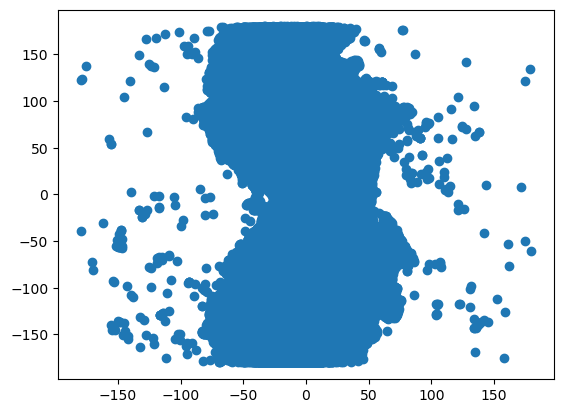

In [399]:
plt.scatter(tracking_data['another_hd_mystery'], tracking_data['hd_mystery'])
plt.show()

Mean circular difference with hd_mystery: 92.00064376257355
Mean circular difference with another_hd_mystery: 85.0021269654001
Mean circular difference between hd_mystery and another_hd_mystery: 115.44934562785467


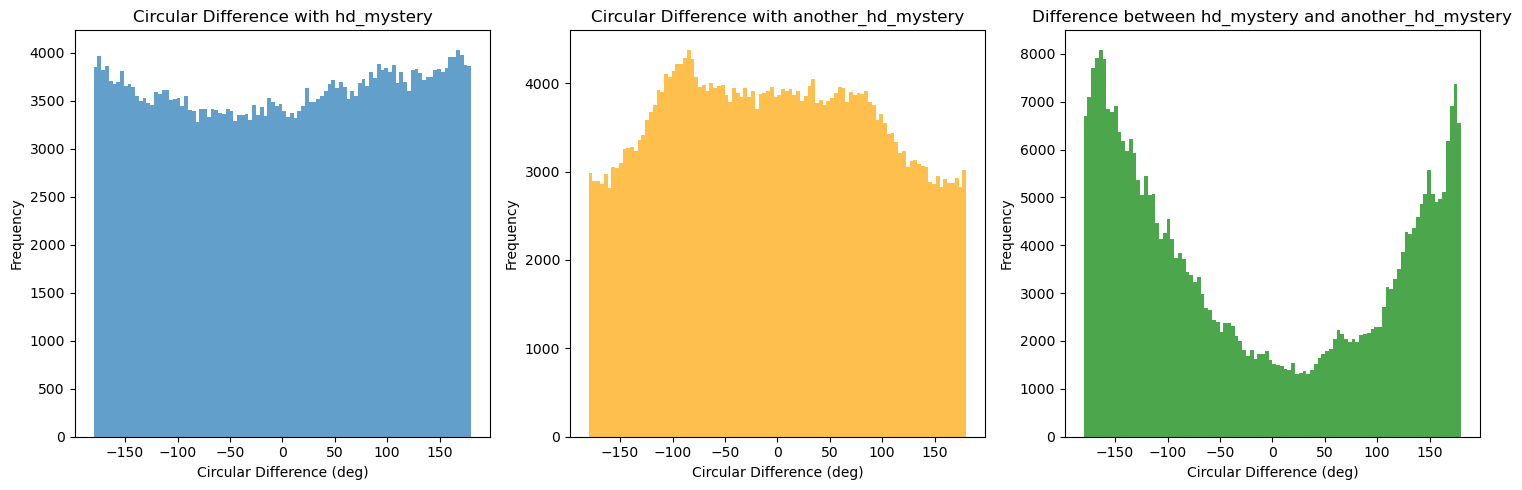

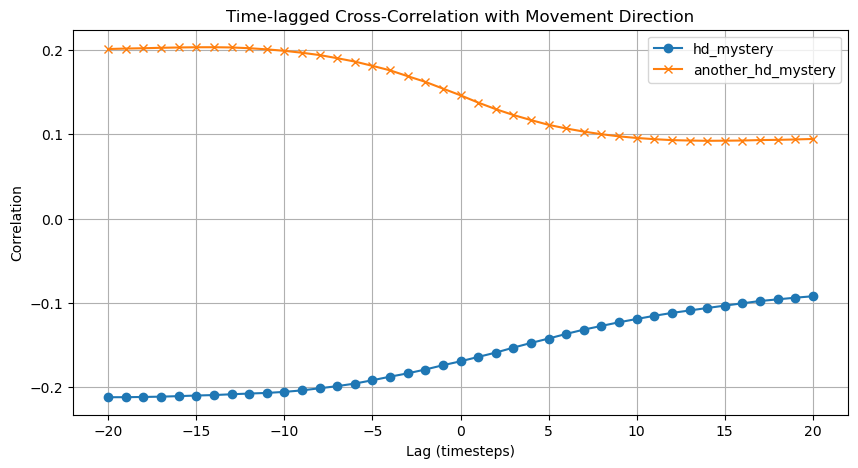

In [400]:
df = tracking_data

dx = df['x'].diff()
dy = df['y'].diff()
movement_direction = np.degrees(np.arctan2(dy, dx))

# Normalize angles to the range [-180, 180]
def circular_diff(a, b):
    diff = a - b
    return (diff + 180) % 360 - 180

# Add the calculated movement direction to the dataframe
df['calculated_movement_direction'] = movement_direction

# Compute circular differences
df['diff_hd_mystery'] = circular_diff(df['calculated_movement_direction'], df['hd_mystery'])
df['diff_another_hd_mystery'] = circular_diff(df['calculated_movement_direction'], df['another_hd_mystery'])

# Compute average circular differences
mean_diff_hd_mystery = df['diff_hd_mystery'].abs().mean()
mean_diff_another_hd_mystery = df['diff_another_hd_mystery'].abs().mean()

print(f"Mean circular difference with hd_mystery: {mean_diff_hd_mystery}")
print(f"Mean circular difference with another_hd_mystery: {mean_diff_another_hd_mystery}")

# 1. Difference between hd_mystery and another_hd_mystery
df['diff_hd_vs_another_hd'] = circular_diff(df['hd_mystery'], df['another_hd_mystery'])
mean_diff_hd_vs_another_hd = df['diff_hd_vs_another_hd'].abs().mean()
print(f"Mean circular difference between hd_mystery and another_hd_mystery: {mean_diff_hd_vs_another_hd}")

# 2. Time-lagged cross-correlation analysis
max_lag = 20  # Maximum lag in timesteps
lags = range(-max_lag, max_lag + 1)
cross_corr_hd = [df['calculated_movement_direction'].corr(df['hd_mystery'].shift(lag)) for lag in lags]
cross_corr_another_hd = [df['calculated_movement_direction'].corr(df['another_hd_mystery'].shift(lag)) for lag in lags]

# Plotting circular differences
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.hist(df['diff_hd_mystery'].dropna(), bins=100, alpha=0.7, label='hd_mystery')
plt.xlabel('Circular Difference (deg)')
plt.ylabel('Frequency')
plt.title('Circular Difference with hd_mystery')

plt.subplot(1, 3, 2)
plt.hist(df['diff_another_hd_mystery'].dropna(), bins=100, alpha=0.7, label='another_hd_mystery', color='orange')
plt.xlabel('Circular Difference (deg)')
plt.ylabel('Frequency')
plt.title('Circular Difference with another_hd_mystery')

plt.subplot(1, 3, 3)
plt.hist(df['diff_hd_vs_another_hd'].dropna(), bins=100, alpha=0.7, label='hd_vs_another_hd', color='green')
plt.xlabel('Circular Difference (deg)')
plt.ylabel('Frequency')
plt.title('Difference between hd_mystery and another_hd_mystery')

plt.tight_layout()
plt.show()

# Plot time-lagged cross-correlation
plt.figure(figsize=(10, 5))
plt.plot(lags, cross_corr_hd, label='hd_mystery', marker='o')
plt.plot(lags, cross_corr_another_hd, label='another_hd_mystery', marker='x')
plt.xlabel('Lag (timesteps)')
plt.ylabel('Correlation')
plt.title('Time-lagged Cross-Correlation with Movement Direction')
plt.legend()
plt.grid(True)
plt.show()

In [540]:
positions = tracking_data[['timestamp', 'x', 'y', 'another_hd_mystery']].to_numpy()
positions[:5]

array([[ 2.739056e+03,  2.525570e-01, -4.098500e-02,  1.560136e+01],
       [ 2.739066e+03,  2.523290e-01, -4.047900e-02,  1.540552e+01],
       [ 2.739076e+03,  2.520940e-01, -4.003500e-02,  1.511357e+01],
       [ 2.739086e+03,  2.518640e-01, -3.961000e-02,  1.466914e+01],
       [ 2.739096e+03,  2.516220e-01, -3.920200e-02,  1.433934e+01]])

In [507]:
position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])

positions = positions[position_mask]

In [510]:
np.min(positions[:, 3])

-179.9991

In [511]:
positions[:, 3] += abs(np.min(positions[:, 3])) # normalize to 0 to 360 scale
positions[:, 1] += abs(np.min(positions[:, 1]))
positions[:, 2] += abs(np.min(positions[:, 2]))

In [357]:
np.min(tracking_data['mystery1']) # uhhh also 'y' seem to be between -180 and 180
# 'x' is between -78 and 72
# mystery 1 is between -0.

-0.18664

In [295]:
meanfr = loadmat(f'/home/mag/Space/data/dusz/Dataset_1/{rat}/Analysis/MeanFR.mat', struct_as_record=False, squeeze_me=True)
meanfr.keys()



dict_keys(['__header__', '__version__', '__globals__', 'ratwREM', 'ratwREM_Info', 'rateS', 'rateS_Info', 'rateT', 'rateT_Info', 'rateREM', 'rateREM_Info'])

In [299]:
square_rate = extract_matlab_obj(meanfr['rateS'])
square_rate.shape

(55,)

In [548]:
dataset = 1
rat = 'A5505-200831'
epochs = loadmat(f'/home/mag/Space/data/dusz/Dataset_{dataset}/{rat}/Data/BehavEpochs.mat', struct_as_record=False, squeeze_me=True)
epochs.keys()


dict_keys(['__header__', '__version__', '__globals__', 'sleep1Ep', 'sleep1Ep_Info', 'wake1Ep', 'wake1Ep_Info', 'sleep2Ep', 'sleep2Ep_Info', 'wake2Ep', 'wake2Ep_Info'])

In [479]:
epoch_data = extract_matlab_obj(epochs['wake1Ep'])

In [480]:
epoch_data

{'units': {'quantity': 'time', 'unit': 'ts', 'value': 1},
 'start': 2735.856,
 'stop': 3648.348}

In [549]:
pos = loadmat(f'/home/mag/Space/data/dusz/Dataset_1/{rat}/Data/Position.mat', struct_as_record=False, squeeze_me=True)
pos.keys()

dict_keys(['__header__', '__version__', '__globals__', 'pos', 'pos_Info'])

In [550]:
pos

{'__header__': b'MATLAB 5.0 MAT-file, Platform: MACI64, Created on: Tue Mar 14 19:40:49 2023',
 '__version__': '1.0',
 '__globals__': [],
 'pos': array([[ 7.76928, 64.65952],
        [ 8.0208 , 64.84512],
        [ 8.26496, 65.04272],
        ...,
        [50.69632,  3.92496],
        [50.61824,  4.01264],
        [50.52816,  4.09952]]),
 'pos_Info': 'No info'}

In [551]:
pos = extract_matlab_obj(pos['pos'])
pos

array([[ 7.76928, 64.65952],
       [ 8.0208 , 64.84512],
       [ 8.26496, 65.04272],
       ...,
       [50.69632,  3.92496],
       [50.61824,  4.01264],
       [50.52816,  4.09952]])

In [410]:
positions[:, 1].shape

(180226,)

In [278]:
ahv = loadmat(f'/home/mag/Space/data/dusz/Dataset_1/{rat}/Data/Ahv.mat', struct_as_record=False, squeeze_me=True)
ahv.keys()


dict_keys(['__header__', '__version__', '__globals__', 'ahv', 'ahv_Info'])

In [280]:
ahv = extract_matlab_obj(ahv['ahv'])
ahv


{'t': array([ 3760.864,  3760.874,  3760.884, ..., 11186.85 , 11186.86 ,
        11186.87 ]),
 'data': array([  73.43870803,   65.90794619,   55.38219577, ..., -375.64206289,
        -385.80596697, -389.47960798])}

In [557]:
np.nanmax(ahv['data'])
# I'm gonna leave the pos stuff behind for now

725.5844234053706

In [552]:
angle = loadmat(f'/home/mag/Space/data/dusz/Dataset_1/{rat}/Data/Angle.mat', struct_as_record=False, squeeze_me=True)
angle.keys()

dict_keys(['__header__', '__version__', '__globals__', 'ang', 'ang_Info'])

In [553]:
angle = extract_matlab_obj(angle['ang'])
angle

{'t': array([ 3760.864,  3760.874,  3760.884, ..., 11186.86 , 11186.87 ,
        11186.88 ]),
 'data': array([-0.77228184, -0.75590995, -0.73158879, ..., -0.84782405,
        -0.92800116, -1.00048416])}

In [422]:
angle['data'][:] += 3.1415804362850293 # why would you not just do 0 to 2pi


In [555]:
angle_degs = np.degrees(angle['data'])
angle_degs.shape
angle_data = np.column_stack((angle['t'], angle_degs))
angle_data[:20]
# ok so column 3 is indeed movement dir!

array([[3760.864  ,  -44.24849],
       [3760.874  ,  -43.31045],
       [3760.884  ,  -41.91695],
       [3760.894  ,  -41.17005],
       [3760.904  ,  -40.9854 ],
       [3760.914  ,  -41.12223],
       [3760.924  ,  -41.04427],
       [3760.934  ,  -40.39972],
       [3760.944  ,  -40.35862],
       [3760.954  ,  -40.88781],
       [3760.964  ,  -40.54615],
       [3760.974  ,  -39.84567],
       [3760.984  ,  -39.30769],
       [3760.994  ,  -38.79053],
       [3761.004  ,  -38.17746],
       [3761.014  ,  -37.23075],
       [3761.024  ,  -36.38272],
       [3761.034  ,  -35.6507 ],
       [3761.044  ,  -35.4719 ],
       [3761.054  ,  -35.11708]])

In [249]:
vel = loadmat(f'/home/mag/Space/data/dusz/Dataset_1/{rat}/Data/Velocity.mat', struct_as_record=False, squeeze_me=True)
vel.keys()

dict_keys(['__header__', '__version__', '__globals__', 'vel', 'vel_Info'])

In [250]:
vel = extract_matlab_obj(vel['vel'])

velocity = np.array([[t, d] for t, d in zip(vel['t'], vel['data'])])
velocity[0]

array([2739.056     ,    8.02325956])

In [311]:
velocity[:10, 0]

array([2739.056, 2739.066, 2739.076, 2739.086, 2739.096, 2739.106,
       2739.116, 2739.126, 2739.136, 2739.146])

In [312]:
angle['t'][:10]

array([2739.046, 2739.056, 2739.066, 2739.076, 2739.086, 2739.096,
       2739.106, 2739.116, 2739.126, 2739.136])

In [253]:
np.mean(velocity[:,1])
# can zip vel and angle together on timestamps but where the hell is the pos timestamping??

9.639709526988192

In [487]:
types = loadmat(f'/home/mag/Space/data/dusz/Dataset_{dataset}/{rat}/Data/CellTypes.mat', struct_as_record=False, squeeze_me=True)
types.keys()


dict_keys(['__header__', '__version__', '__globals__', 'gd', 'gd_Info', 'hd', 'hd_Info', 'fs', 'fs_Info', 'ex', 'ex_Info', 'nhd', 'nhd_Info'])

In [532]:
hd_list = extract_matlab_obj(types['hd'])
good_list = extract_matlab_obj(types['gd'])
excit_list = extract_matlab_obj(types['ex'])
hd_list

array([0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0], dtype=uint8)

In [529]:
excit_list

array([0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0], dtype=uint8)

In [535]:
excit_list = np.logical_and(np.logical_not(hd_list).astype(int), excit_list)#, good_list)

In [536]:
len(np.where(excit_list == True)[0])

3

In [491]:
# I'm just going to use their stuff for this tbh
data = loadmat(f'/home/mag/Space/data/dusz/Dataset_1/{rat}/Data/SpikeData.mat', struct_as_record=False, squeeze_me=True)
data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'S', 'S_Info', 'shank', 'shank_Info', 'cellIx', 'cellIx_Info'])

In [492]:
from scipy.io.matlab._mio5_params import mat_struct

def extract_matlab_obj(obj):
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}

    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

In [493]:
obj = extract_matlab_obj(data['S'])

In [449]:
obj

{'C': array([{'tsd': {'t': array([   16.0727 ,    16.934  ,    17.1169 , ..., 11189.3144 ,
               11189.3306 , 11189.35675]), 'data': array([], dtype=float64)}}        ,
        {'tsd': {'t': array([   65.59915,    70.6782 ,    78.31655, ..., 11181.99365,
               11182.03675, 11188.85315]), 'data': array([], dtype=float64)}}        ,
        {'tsd': {'t': array([1.37500000e-02, 1.87700000e-01, 2.70200000e-01, ...,
               1.11861032e+04, 1.11867265e+04, 1.11867486e+04]), 'data': array([], dtype=float64)}},
        {'tsd': {'t': array([2.56340000e+00, 2.62805000e+00, 2.66615000e+00, ...,
               1.11853371e+04, 1.11853530e+04, 1.11870287e+04]), 'data': array([], dtype=float64)}},
        {'tsd': {'t': array([1.22790000e+00, 1.69860000e+00, 1.81725000e+00, ...,
               1.11868928e+04, 1.11869214e+04, 1.11869489e+04]), 'data': array([], dtype=float64)}},
        {'tsd': {'t': array([1.81250000e-01, 1.92000000e-01, 1.95900000e-01, ...,
               1.1

In [494]:
arr = []

for a in obj['C']:
    arr.append(a['tsd']['t'])

# now I have a list of spike times per neuron

# turn it into a list of spike times with the neuron id

full_arr = []

for i, a in enumerate(arr):
    for aa in a:
        full_arr.append([aa, i])

spike_times = np.array(full_arr)
spike_times = spike_times[np.argsort(spike_times[:, 0])]


In [495]:
spike_mask = (spike_times[:, 0] > epoch_data['start']) & (spike_times[:, 0] < epoch_data['stop'])
spike_times = spike_times[spike_mask]

In [496]:
np.max(spike_times)

3648.34795

In [537]:
np.where(excit_list == 1)

(array([31, 58, 99]),)

In [538]:
rate_maps, hd_rate_map, hd_rate_map_fold0, hd_rate_map_fold1, hd_occupancy_map, raw_hd_rate_maps = get_rate_maps(spike_times, positions, np.where(excit_list == 1)[0])

Seed 111


100%|█████████████████████████████████████████████████████████████████████████| 101/101 [00:00<00:00, 16864.04it/s]


# neurons: 3


100%|██████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 2720.63it/s]


Unpack freq maps


3it [00:00, 3954.40it/s]


Creating rate maps


100%|██████████████████████████████████████████████████████████████████████████████| 11/11 [00:06<00:00,  1.72it/s]

Runtime: 0.16 minutes


In [539]:
save_path = f'/home/mag/Space/results/dusz/Dataset_{dataset}/{rat}'
try:
    os.mkdir(save_path)
except FileExistsError:
    pass

hd_bin_count=17

np.save(f'{save_path}/rate_maps_hd_bin_count_{hd_bin_count}', rate_maps)
np.save(f'{save_path}/hd_rate_map_hd_bin_count_{hd_bin_count}', hd_rate_map)
np.save(f'{save_path}/hd_rate_map_fold0_hd_bin_count_{hd_bin_count}', hd_rate_map_fold0)
np.save(f'{save_path}/hd_rate_map_fold1_hd_bin_count_{hd_bin_count}', hd_rate_map_fold1)
np.save(f'{save_path}/hd_occupancy_map_hd_bin_count_{hd_bin_count}', hd_occupancy_map)
np.save(f'{save_path}/raw_hd_rate_maps_hd_bin_count_{hd_bin_count}', raw_hd_rate_maps)

In [522]:
rat

'A1808-190807'

In [518]:
np.max(positions[:, 3])

359.9986

### Analysis

In [519]:
import numpy as np
import time
from tqdm import tqdm
from joblib import Parallel, delayed

def get_rate_maps(spike_times, positions, excit_list, hd_bin_count=17, filter_vel=False):
    # --- PARAMETERS ---
    seed = 111
    np.random.seed(seed=seed)
    
    timebin_tol = 1e-4
    tau = 0.120  # approx 8hz (.25 from pfeiffer was averaging over two cycles so didn't make a lot of sense)
    interpolation_points = 2
    velocity_threshold = 5  # cm/s
    env_len = max(np.max(positions[:, 1]), np.max(positions[:, 2])) #90  # cm
    hd_max = np.max(positions[:, 3])
    bin_count = 11  # approximately the same cm per bin as pfeiffer
    bin_width = env_len / bin_count
    
    start_time = time.time()
    print(f"Seed {seed}")
    
    base_time = np.arange(spike_times[0, 0], spike_times[-1, 0], tau)
    
    # --- SPIKE DATA SEPARATION (EXCITATORY NEURONS) ---
    neuron_idxs = set(spike_times[:, 1])
    spike_mat = []
    for i in tqdm(neuron_idxs):
        if int(i) in excit_list:
            spike_mat.append(spike_times[spike_times[:, 1] == i])
    n_neurons = len(spike_mat)
    print(f"# neurons: {n_neurons}")
    
    # --- VELOCITY FILTERING ---
    '''
    time_step_gap = positions[3, 0] - positions[2, 0]
    point_steps = np.diff(positions[:, 1:3], axis=0)
    point_steps = np.vstack((point_steps, point_steps[-1]))
    point_dist = np.linalg.norm(point_steps, axis=1) / time_step_gap
    
    # Instead of a Python loop, use np.searchsorted to quickly gather indices
    bin_indices = np.searchsorted(base_time, positions[:, 0]) - 1
    # remove out-of-range indices
    valid_mask = (bin_indices >= 0) & (bin_indices < len(base_time) - 1)
    bin_indices = bin_indices[valid_mask]
    point_dist_valid = point_dist[valid_mask]
    
    # sum distances in each bin, then divide by the count
    sum_dist = np.bincount(bin_indices, weights=point_dist_valid)
    count_dist = np.bincount(bin_indices)
    with np.errstate(divide='ignore', invalid='ignore'):
        vel_list = sum_dist / count_dist
    vel_list[np.isnan(vel_list)] = 0  # bins that had no visits -> 0 or whatever default
    
    # match the final size to len(base_time)
    if len(vel_list) < len(base_time):
        vel_list = np.pad(vel_list, (0, len(base_time) - len(vel_list)), 'constant')
    
    # filter out time bins with velocity < velocity_threshold
    fast_indices = np.where(vel_list >= velocity_threshold)[0]
    fast_bins = base_time[fast_indices] if filter_vel else base_time
    '''
    fast_bins = base_time
    # if you already have a list of velocities just use that :)
    
    
    # --- FREQUENCY MAPS ---
    freq_maps = np.empty((len(base_time), 2, n_neurons))
    
    def compute_freq_map_for_neuron(i, spike_mat_i, base_time, tau):
        """Compute the frequency map for the i-th neuron."""
        current_map = np.vstack((base_time, np.empty(len(base_time)))).T
        for j in range(len(base_time) - 1):
            running_freq = len(np.where(
                (spike_mat_i[:, 0] <= base_time[j + 1]) &
                (spike_mat_i[:, 0] > base_time[j])
            )[0]) / tau
            current_map[j, 1] = running_freq
        return current_map
        
    # Parallel processing for each neuron
    results = Parallel(n_jobs=-1)(delayed(compute_freq_map_for_neuron)(
        i, spike_mat[i], base_time, tau
    ) for i in tqdm(range(n_neurons)))
        
    # Put the results into freq_maps
    print("Unpack freq maps")
    for i, current_map in tqdm(enumerate(results)):
        freq_maps[:, :, i] = current_map
    
    # --- BUILD SPATIAL + HEAD-DIRECTION RATE MAPS ---
    spatial_bins = np.linspace(0, env_len, bin_count + 1)
    rate_maps = np.zeros((bin_count, bin_count, n_neurons))
    
    hd_bins = np.linspace(0, hd_max, hd_bin_count + 1)
    hd_rate_map = np.zeros((bin_count, bin_count, hd_bin_count, n_neurons))
    hd_occupancy_map = np.zeros((bin_count, bin_count, hd_bin_count))
    hd_rate_map_fold0 = np.zeros((bin_count, bin_count, hd_bin_count, n_neurons))
    hd_rate_map_fold1 = np.zeros((bin_count, bin_count, hd_bin_count, n_neurons))
    raw_hd_rate_maps = np.zeros((bin_count, bin_count, 13959, hd_bin_count, n_neurons))  # max num of visits
    
    # use np.nan to distinguish no visits from zero activation
    raw_hd_rate_maps[:] = np.nan
    hd_rate_map[:] = np.nan
    hd_rate_map_fold0[:] = np.nan
    hd_rate_map_fold1[:] = np.nan
    
    print("Creating rate maps")
    for i in tqdm(range(len(spatial_bins) - 1)):
        for j in range(len(spatial_bins) - 1):
            freq_locs = np.where(
                (positions[:, 1] <= spatial_bins[i + 1]) &
                (positions[:, 1] >= spatial_bins[i]) &
                (positions[:, 2] <= spatial_bins[j + 1]) &
                (positions[:, 2] >= spatial_bins[j])
            )[0]
    
            if freq_locs.size > 5:
                # the time bins during which the rat is in that location
                freq_locers = np.array([
                    np.abs(base_time - positions[idx, 0]).argmin()
                    for idx in freq_locs
                ])
    
                # filter by velocity threshold
                mask = np.any(np.isclose(base_time[freq_locers, None], fast_bins, atol=timebin_tol), axis=1)
                freq_locers = freq_locers[mask]
    
                all_hd_freq_locs = []
                for l in range(len(hd_bins) - 1):
                    hd_freq_locs = np.where(
                        (positions[freq_locs, 3] >= hd_bins[l]) &
                        (positions[freq_locs, 3] < hd_bins[l + 1])
                    )[0]
                    hd_freq_locs = freq_locs[hd_freq_locs]
    
                    hd_occupancy_map[i, j, l] = len(hd_freq_locs)
    
                    if hd_freq_locs.size > 2:
                        all_hd_freq_locs.append(hd_freq_locs)
    
                        hd_freq_locers = np.array([
                            np.abs(base_time - positions[idx, 0]).argmin()
                            for idx in hd_freq_locs
                        ])
                        mask = np.any(np.isclose(base_time[hd_freq_locers, None], fast_bins, atol=timebin_tol), axis=1)
                        hd_freq_locers = hd_freq_locers[mask]
    
                        hd_rate_map[i, j, l] = np.mean(freq_maps[hd_freq_locers, 1, :], axis=0)
    
                        np.random.shuffle(hd_freq_locers)
                        hd_rate_map_fold0[i, j, l] = np.mean(
                            freq_maps[hd_freq_locers, 1, :][:len(hd_freq_locers) // 2], axis=0
                        )
                        hd_rate_map_fold1[i, j, l] = np.mean(
                            freq_maps[hd_freq_locers, 1, :][len(hd_freq_locers) // 2:], axis=0
                        )
    
                        n = hd_freq_locers.shape[0]
                        raw_hd_rate_maps[i, j, :n, l, :] = freq_maps[hd_freq_locers, 1, :]
    
                # Compute the spatial rate map by combining all HD bins
                if len(all_hd_freq_locs) == 0:
                    rate_maps[i, j, :] = np.nan
                else:
                    freq_locs = np.concatenate(all_hd_freq_locs)
                    freq_locers = np.array([
                        np.abs(base_time - positions[idx, 0]).argmin()
                        for idx in freq_locs
                    ])
                    rate_maps[i, j] = np.nanmean(freq_maps[freq_locers, 1, :], axis=0)

    runtime = (time.time() - start_time) / 60
    print(f"Runtime: {runtime:.2f} minutes")
    
    return rate_maps, hd_rate_map, hd_rate_map_fold0, hd_rate_map_fold1, hd_occupancy_map, raw_hd_rate_maps

In [460]:
# loop through em all

def rate_maps_per_session(session):
    filepath = os.listdir(f'{data_path}/{session}')[0]
    print(filepath)
    
    io = NWBHDF5IO(f'{data_path}/{session}/{filepath}', mode="r")
    nwbfile = io.read()

    headings = nwbfile.processing['behavior'].data_interfaces['CompassDirection'].spatial_series['head-direction'].data[:]   # rad
    positions = nwbfile.processing['behavior'].data_interfaces['Position'].spatial_series['position'].data[:]                # cm
    ts = nwbfile.processing['behavior'].data_interfaces['CompassDirection'].spatial_series['head-direction'].timestamps[:]
    
    positions = np.hstack((ts.reshape(-1, 1), positions, headings.reshape(-1, 1)))
    
    epochs_df = nwbfile.epochs[:] # dataframe of start/stop times for positions
    explore_start = epochs_df['start_time'].loc[1]
    explore_stop = epochs_df['stop_time'].loc[1]
    
    units_df = nwbfile.units[:]
    spike_times = []
    for i, row in units_df.iterrows():
        spike_times.extend([[st, i] for st in row['spike_times']])
    spike_times = np.array(spike_times)
    spike_times = np.sort(spike_times, axis=0)
    spike_times = spike_times[(explore_start < spike_times[:, 0]) & (spike_times[:, 0] < explore_stop)]
    
    positions = positions[(explore_start < positions[:, 0]) & (positions[:, 0] < explore_stop)]
    
    # Extract other columns as lists
    excit_list = set(np.where(units_df['is_excitatory'].values == 1)[0])
    is_head_dir = set(np.where(units_df['is_head_direction'].values == 1)[0])

    positions[:, 1] += abs(np.min(positions[:, 1]))
    positions[:, 2] += abs(np.min(positions[:, 2]))

    hd_bin_count = 17
    
    rate_maps, hd_rate_map, hd_rate_map_fold0, hd_rate_map_fold1, hd_occupancy_map, raw_hd_rate_maps = get_rate_maps(spike_times, positions, excit_list, is_head_dir, hd_bin_count)

    save_path = f'/home/mag/Space/results/dusz/{session}'
    try:
        os.mkdir(save_path)
    except FileExistsError:
        pass
    
    np.save(f'{save_path}/rate_maps_hd_bin_count_{hd_bin_count}', rate_maps)
    np.save(f'{save_path}/hd_rate_map_hd_bin_count_{hd_bin_count}', hd_rate_map)
    np.save(f'{save_path}/hd_rate_map_fold0_hd_bin_count_{hd_bin_count}', hd_rate_map_fold0)
    np.save(f'{save_path}/hd_rate_map_fold1_hd_bin_count_{hd_bin_count}', hd_rate_map_fold1)
    np.save(f'{save_path}/hd_occupancy_map_hd_bin_count_{hd_bin_count}', hd_occupancy_map)
    np.save(f'{save_path}/raw_hd_rate_maps_hd_bin_count_{hd_bin_count}', raw_hd_rate_maps)


In [462]:
import os

data_path = '/home/mag/Space/data/dusz/Dataset_6/'

for d in os.listdir(data_path):
    if '-' in d:
        rate_maps_per_session(d)

Data


NameError: name 'NWBHDF5IO' is not defined

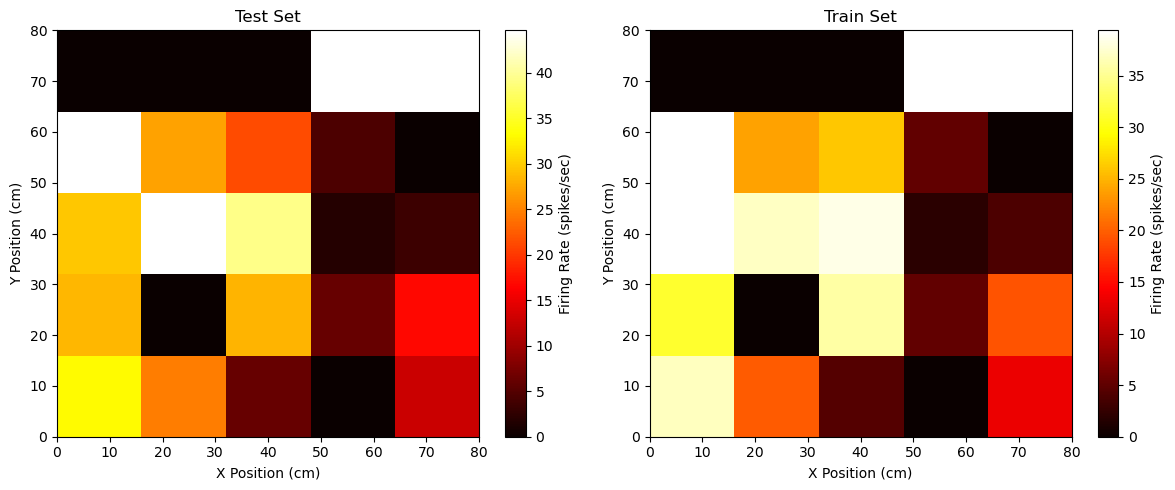

In [86]:
import matplotlib.pyplot as plt

dataset = 'dusz'
session = 'sub-A3716'

hd_rate_map_test = np.load(f'results/{dataset}/{session}/hd_rate_map_fold0_hd_bin_count_17.npy')
hd_rate_map_train = np.load(f'results/{dataset}/{session}/hd_rate_map_fold1_hd_bin_count_17.npy')

nbins = 8
envLen = 80
bin_size = envLen // nbins

neuron_idx = 5

smoothed_firing_rate_test = np.mean(hd_rate_map_test[:, :, :, neuron_idx], axis=2)
smoothed_firing_rate_train = np.mean(hd_rate_map_train[:, :, :, neuron_idx], axis=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(smoothed_firing_rate_test, 
                     extent=[0, nbins*bin_size, 0, nbins*bin_size],
                     origin='lower', aspect='auto', cmap='hot')
axes[0].set_title('Test Set')
axes[0].set_xlabel('X Position (cm)')
axes[0].set_ylabel('Y Position (cm)')

im2 = axes[1].imshow(smoothed_firing_rate_train,
                     extent=[0, nbins*bin_size, 0, nbins*bin_size],
                     origin='lower', aspect='auto', cmap='hot')
axes[1].set_title('Train Set')
axes[1].set_xlabel('X Position (cm)')
axes[1].set_ylabel('Y Position (cm)')

fig.colorbar(im1, ax=axes[0], label='Firing Rate (spikes/sec)')
fig.colorbar(im2, ax=axes[1], label='Firing Rate (spikes/sec)')

plt.tight_layout()
plt.show()

# I need to color the nans differently


In [54]:
# doesn't hd need a circular measure? since 0 and 2 pi should induce little variability
smoothed_firing_rate_test[1,5]

nan

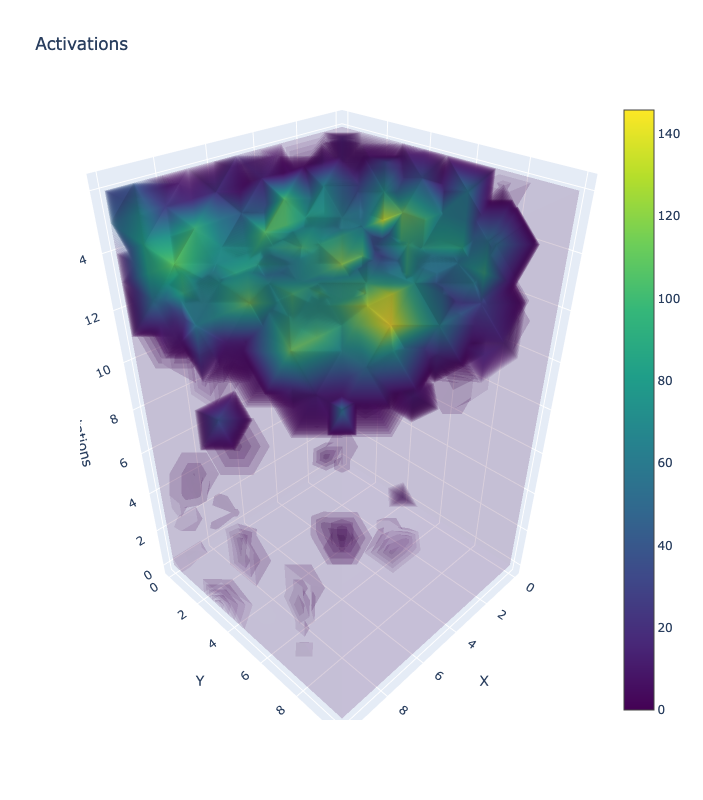

In [547]:
import numpy as np
import plotly.graph_objects as go

path = '/home/mag/Space/results/dusz/Dataset_6/A1110-180612'
hdBinCount = 17
heatmap = np.load(f'{path}/hd_rate_map_n_hd_bins_{hdBinCount}.npy')[:, :, :, 2]

n_bins = heatmap.shape[0]
n_rotations = hdBinCount

x, y, z = np.meshgrid(np.arange(n_bins), np.arange(n_bins), np.arange(n_rotations))

x_flat = x.flatten()
y_flat = y.flatten()
z_flat = z.flatten()
data_flat = heatmap.flatten()

fig = go.Figure(data=go.Volume(
    x=x_flat,
    y=y_flat,
    z=z_flat,
    value=data_flat,
    opacity=0.1,
    isomin=np.min(heatmap),   
    isomax=np.max(heatmap),  
    surface_count=250,
    colorscale='Viridis'
))

fig.update_layout(
    title=f"Activations",
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Rotations',
        xaxis=dict(nticks=10),
        yaxis=dict(nticks=10),
        zaxis=dict(nticks=10),
    ),
    width=800,
    height=800
)

fig.show()

In [96]:
heatmap.shape

(11, 11, 17, 27)